# 3. Only two years of data? Start from another city's model

Learned models need history. **Lakeside** (made up, 7 districts) has only 2.3 years. The graph model's weights don't depend on how many areas a city has, so a model trained in a city with more history can be applied here, with no training at all (*zero-shot*) or as a starting point for local training.

In the paper behind this package, a Boston model applied to Columbus with no Columbus training matched a model trained on Columbus itself and beat persistence. That won't hold everywhere, so here, as always, **backtest it on your own data first**.

Pretrained Boston weights will be published with the package's first release. They use weather, so call `city.fetch_weather()` before using them. This notebook trains its own small source model on Riverton instead, without weather, so it runs offline.

> **Speed.** To keep this notebook to about half an hour on a laptop, every learned model below uses a 2-member ensemble (`n_seeds=2`) instead of the default 10. Small ensembles are noisier, so treat the numbers here as a demonstration. For real use, drop the `configs=SMALL` argument.

In [1]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

import areafluforecast as af

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

In [2]:
lakeside = af.City.from_files("data/lakeside_rates.csv", edges="data/lakeside_edges.csv",
                              name="lakeside")
print(lakeside.summary())

lakeside: 7 areas, 122 weeks (2024-02-04 to 2026-05-31), flu season Oct-Mar
  graph: 8 borders between areas
  missing area-weeks: 4.8%
  weather: no | static characteristics: none
  complete seasons available to backtest: none


"Complete seasons available: none" means Lakeside has less than two years of history before any full season. The models can still train on what there is, but it's thin.

## 1. Train a transferable model in a city with more history

`gnn_st_noadapt` is the graph model without its learned city-specific links, which is what makes it portable. `save_models=True` writes a checkpoint per horizon.

In [3]:
riverton = af.City.from_files(
    "data/riverton_rates.csv", areas="data/riverton_districts.geojson", id_col="district",
    area_col="district", anchors=["North Township", "Lake Erin"], name="riverton")

source = af.resolve("gnn_st_noadapt", {"n_seeds": 2, "use_weather": False})
trained = af.forecast(riverton, models=[source], horizons=(1,), backtest=None,
                      save_models=True, out_dir="runs", progress=False)
checkpoint = trained.meta["saved_models"][0]
checkpoint

'runs/riverton/forecast_20261004-232829/models/gnn_st_noadapt_h1.pt'

## 2. Would it have worked in Lakeside?

Backtest Lakeside's 2025-26 season (scored June 2025 to May 2026) with three approaches:

- **pretrained**: the Riverton model applied as is, with no Lakeside training
- **gnn_st_noadapt**: the same model trained only on Lakeside's short history
- **persistence**: "next week looks like this week"

In [4]:
local = af.resolve("gnn_st_noadapt", {"n_seeds": 2, "use_weather": False})
bt = af.backtest(lakeside, models=[local], seasons=[2025], horizons=(1,),
                 init_from=checkpoint, zero_shot=True, out_dir="runs")

Budget: 6 epochs x 1 seeds


--- seed 1 (1/1) ---


lakeside: 7 areas, 122 weeks (2024-02-04 to 2026-05-31), flu season Oct-Mar
  graph: 8 borders between areas
  missing area-weeks: 4.8%
  weather: no | static characteristics: none
  complete seasons available to backtest: none


Epoch 1 |  16.7% | 2025-26 1wk gnn_st_noadapt seed 42 | elapsed 0m24s | left ~2m00s


Epoch 2 |  33.3% | 2025-26 1wk gnn_st_noadapt seed 43 | elapsed 0m51s | left ~1m42s


...

Epoch 4 |  66.7% | 2025-26 1wk seasonal_naive | elapsed 0m51s | left ~0m25s


Epoch 5 |  83.3% | 2025-26 1wk gnn_st_noadapt seed 42 | elapsed 1m00s | left ~0m12s


Epoch 6 | 100.0% | 2025-26 1wk gnn_st_noadapt seed 43 | elapsed 1m07s | left ~0m00s


Outputs: runs/lakeside/backtest_20261004-233645


# Backtest: lakeside

Seasons: 2025-26. Every number is from weeks the models never trained on.

**Relative WIS** is the model's weighted interval score divided by persistence's on the same weeks: below 1 means it beat "next week looks like this week". **p (Holm)** asks whether the weekly gap is bigger than week-to-week noise, adjusted for the number of comparisons.

| weeks ahead | model | WIS | relative WIS | p (Holm) | verdict |
|---|---|---|---|---|---|
| 1 | pretrained | 1.41 | 0.65 | 0.000 | better than persistence |
| 1 | gnn_st_noadapt | 1.75 | 0.81 | 0.004 | better than persistence |
| 1 | seasonal_naive | 6.27 | 2.90 | 0.000 | worse than persistence |

Coverage of the 95% band (should be near 95%):

- gnn_st_noadapt, 1 wk: 86.2%
- persistence, 1 wk: 80.8%
- pretrained, 1 wk: 88.5%
- seasonal_naive, 1 wk: 59.3%


In [5]:
bt.comparison[["model", "wis", "relative_wis", "p_holm", "verdict"]].round(3)

,model,wis,relative_wis,p_holm,verdict
0,gnn_st_noadapt,1.748,0.810,0.004,better than persistence
1,pretrained,1.410,0.653,0.000,better than persistence
2,seasonal_naive,6.270,2.905,0.000,worse than persistence


A relative WIS below 1 means the approach beat persistence on Lakeside's own weeks. If the pretrained model does as well as, or better than, the local one, it's a reasonable choice until Lakeside has a few more seasons of its own.

`zero_shot=False` instead *fine-tunes*: it starts from the Riverton weights and keeps training on Lakeside's data.

## 3. Forecast Lakeside with the pretrained model

In [6]:
fc = af.forecast(lakeside, models=[], horizons=(1,), init_from=checkpoint, zero_shot=True,
                 backtest=bt, out_dir="runs", progress=False)
fc.summary()

,model,horizon,target_date,area,predicted,lower,upper,trust
0,pretrained,1,2026-06-07,Bayfront,2.606576,0.430422,4.782731,better than persistence
1,pretrained,1,2026-06-07,Cedar,3.775159,1.097617,6.452701,better than persistence
2,pretrained,1,2026-06-07,Dunmore,2.959316,0.538690,5.379941,better than persistence
3,pretrained,1,2026-06-07,Elm Park,2.197124,0.150511,4.243736,better than persistence
4,pretrained,1,2026-06-07,Fairview,1.952051,0.043618,3.860484,better than persistence
5,pretrained,1,2026-06-07,Glenwood,2.616390,0.427046,4.805733,better than persistence
6,pretrained,1,2026-06-07,Highland,2.803261,0.439745,5.166776,better than persistence


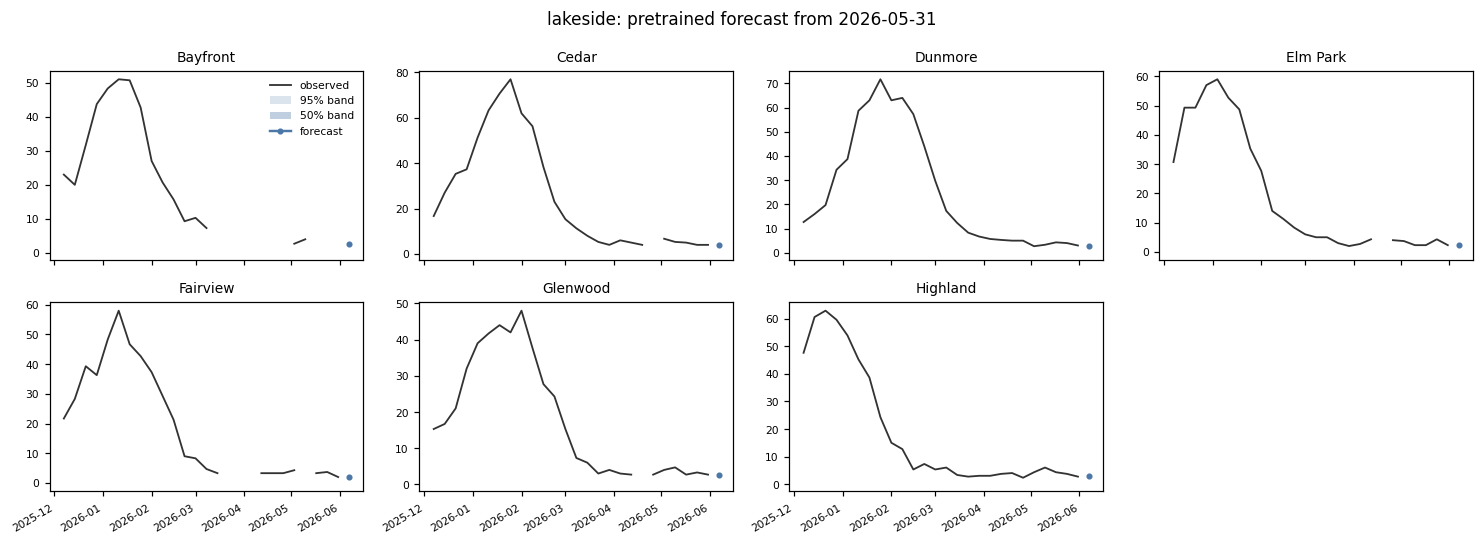

In [7]:
fig = fc.plot(areas=lakeside.areas)